In [1]:
import sys
if "../" not in sys.path:
    sys.path.append("../")
    
import numpy as np
import matplotlib.pyplot as plt
import findiff as fd
import pandas as pd
import scienceplots
from src.wong import WongCrossSection
plt.style.use(['science', 'no-latex', 'ieee'])



import scipy as sp
import os
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic


#size=(6, 6)
#plt.rcParams.update({'figure.figsize': size})
#plt.rcParams.update({'font.size': 20})

#sp.__version__

In [2]:
def sigma(E, A, hbarw, E0):
    R0 = 1.2 * A ** (0.3333)
    return (0.5*R0 **2 * hbarw/ E) * np.log(1 + np.exp(2*np.pi*(E - E0) / hbarw))


def barrier_dist_discrete(e,sigma, acc=4):
    d = fd.FinDiff(0, e, 2, acc=acc)
    barrier_dist = d(sigma*e)
    return (barrier_dist)

def barrier_dist(e,sigma,acc=4):
    d = fd.FinDiff(0, e[1]-e[0], 2, acc=acc)
    barrier_dist = d(sigma*e)
    return (barrier_dist)

def point_diff(x,y,std,dE=1):
    der = np.zeros(x.shape)
    der_err = np.zeros(x.shape)
    for i in range(dE,x.shape[0]-dE):
        der[i] = (2*y[i] - y[i-dE] - y[i+dE]) / (abs(x[i] - x[i-dE]) * abs(x[i]-x[i+dE]))
        der_err[i] = std[i] * np.sqrt(6) * y[i] / (abs(x[i] - x[i-dE]) * abs(x[i]-x[i+dE]))
        # print(i,std[i],y[i],der_err[i])
    
    return der, der_err

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

E = np.linspace(50, 110, 500)
sigma_f = 10*sigma(E, A=208, hbarw=5, E0=75)

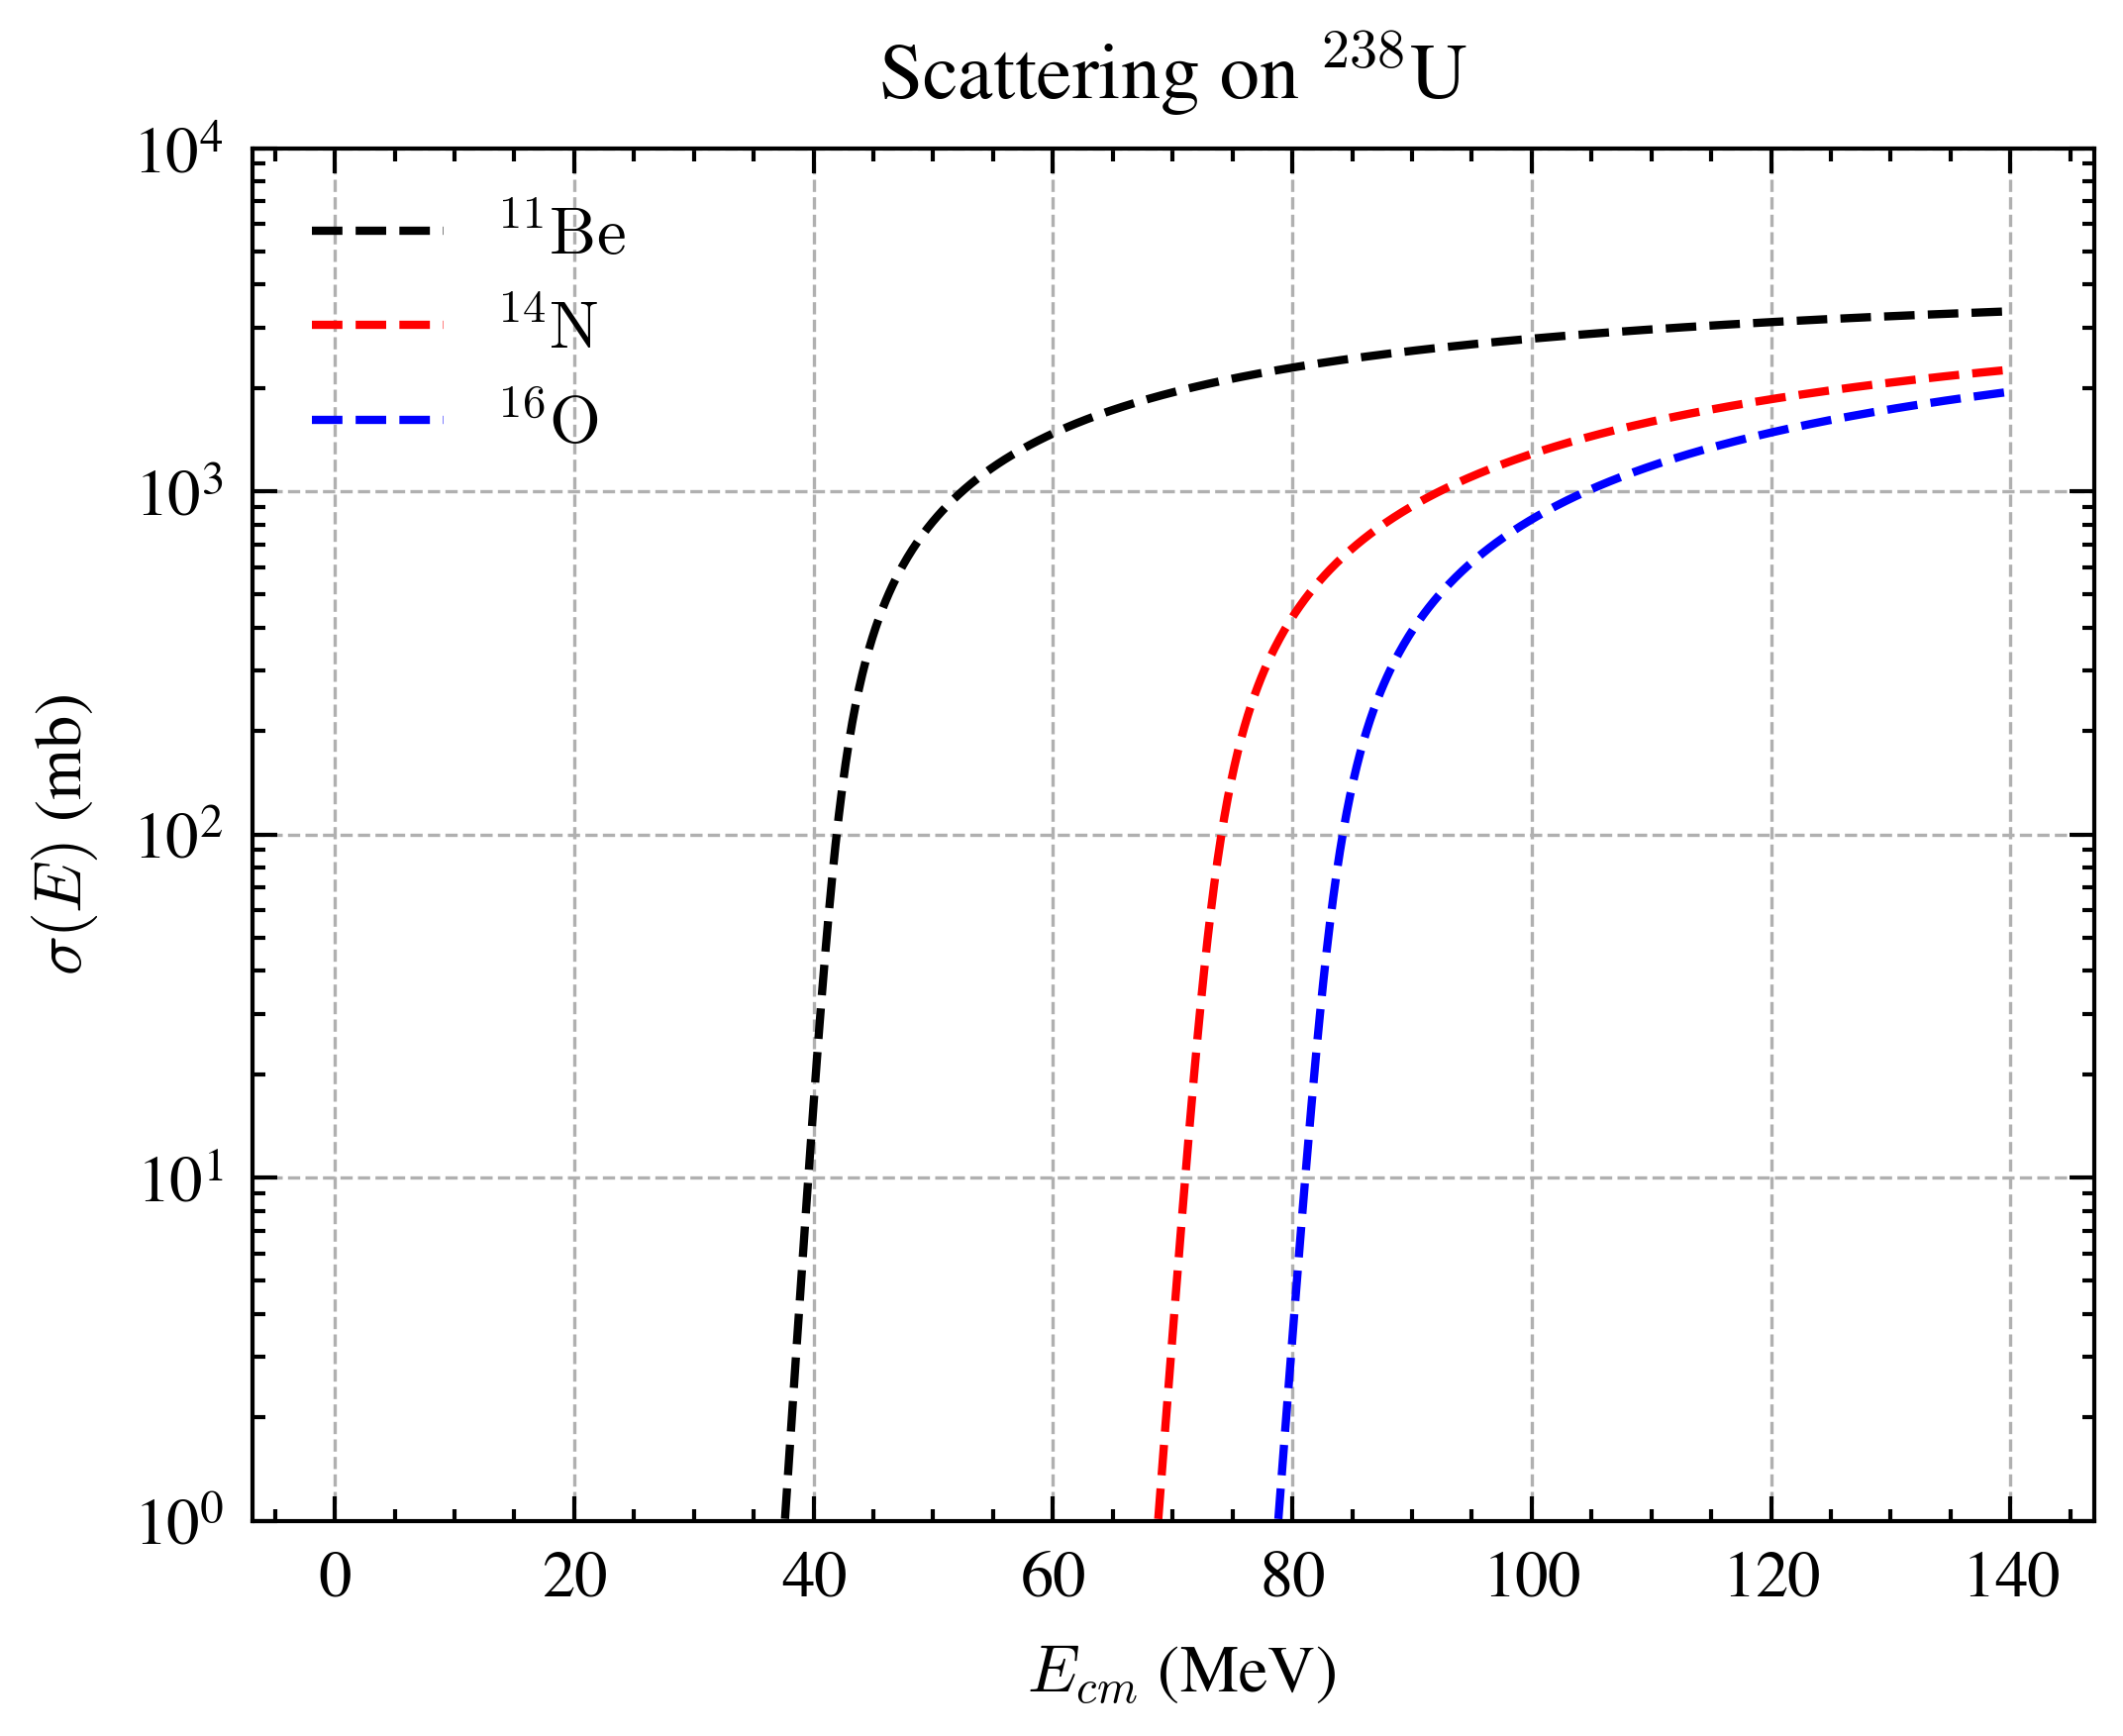

In [5]:
projectiles = [
      #  (r"$^4\mathrm{He}$",  4,  2),
        ( r"$^{11}\mathrm{Be}$", 11, 4),
        (r"$^{14}\mathrm{N}$",  14, 7),
        (r"$^{16}\mathrm{O}$",  16, 8),
      #  ("40Ar", 40, 18),
    ]
# Target: 238U
A_t, Z_t = 238, 92


# Energies from ≈0 (avoid exact zero) up to 140 MeV
Es = np.linspace(0.1, 140.0, 1000)
sigma_all = []

plt.figure(figsize=(4, 3))
for name, A_p, Z_p in projectiles:
    # instantiate the model for each projectile–target pair
    model = WongCrossSection(A_p, Z_p, A_t, Z_t, a=0.48, V0=70.0, r0=1.25)
    sigma_vals = model.sigma(Es)
    sigma_all.append(sigma_vals)
    plt.plot(Es, sigma_vals, label=name, linestyle='--')

plt.yscale("log")
plt.ylim(1, 1e4)
plt.xlabel(" $E_{cm}$ (MeV)")
plt.ylabel("$\\sigma(E)$ (mb)")
plt.title("Scattering on $^{238}$U")
plt.legend(fontsize='medium', loc='best')
plt.grid(linestyle="--", linewidth=0.4)
plt.savefig("../plots/wong-238U.png", bbox_inches='tight', dpi=300)
#plt.tight_layout()
plt.show()

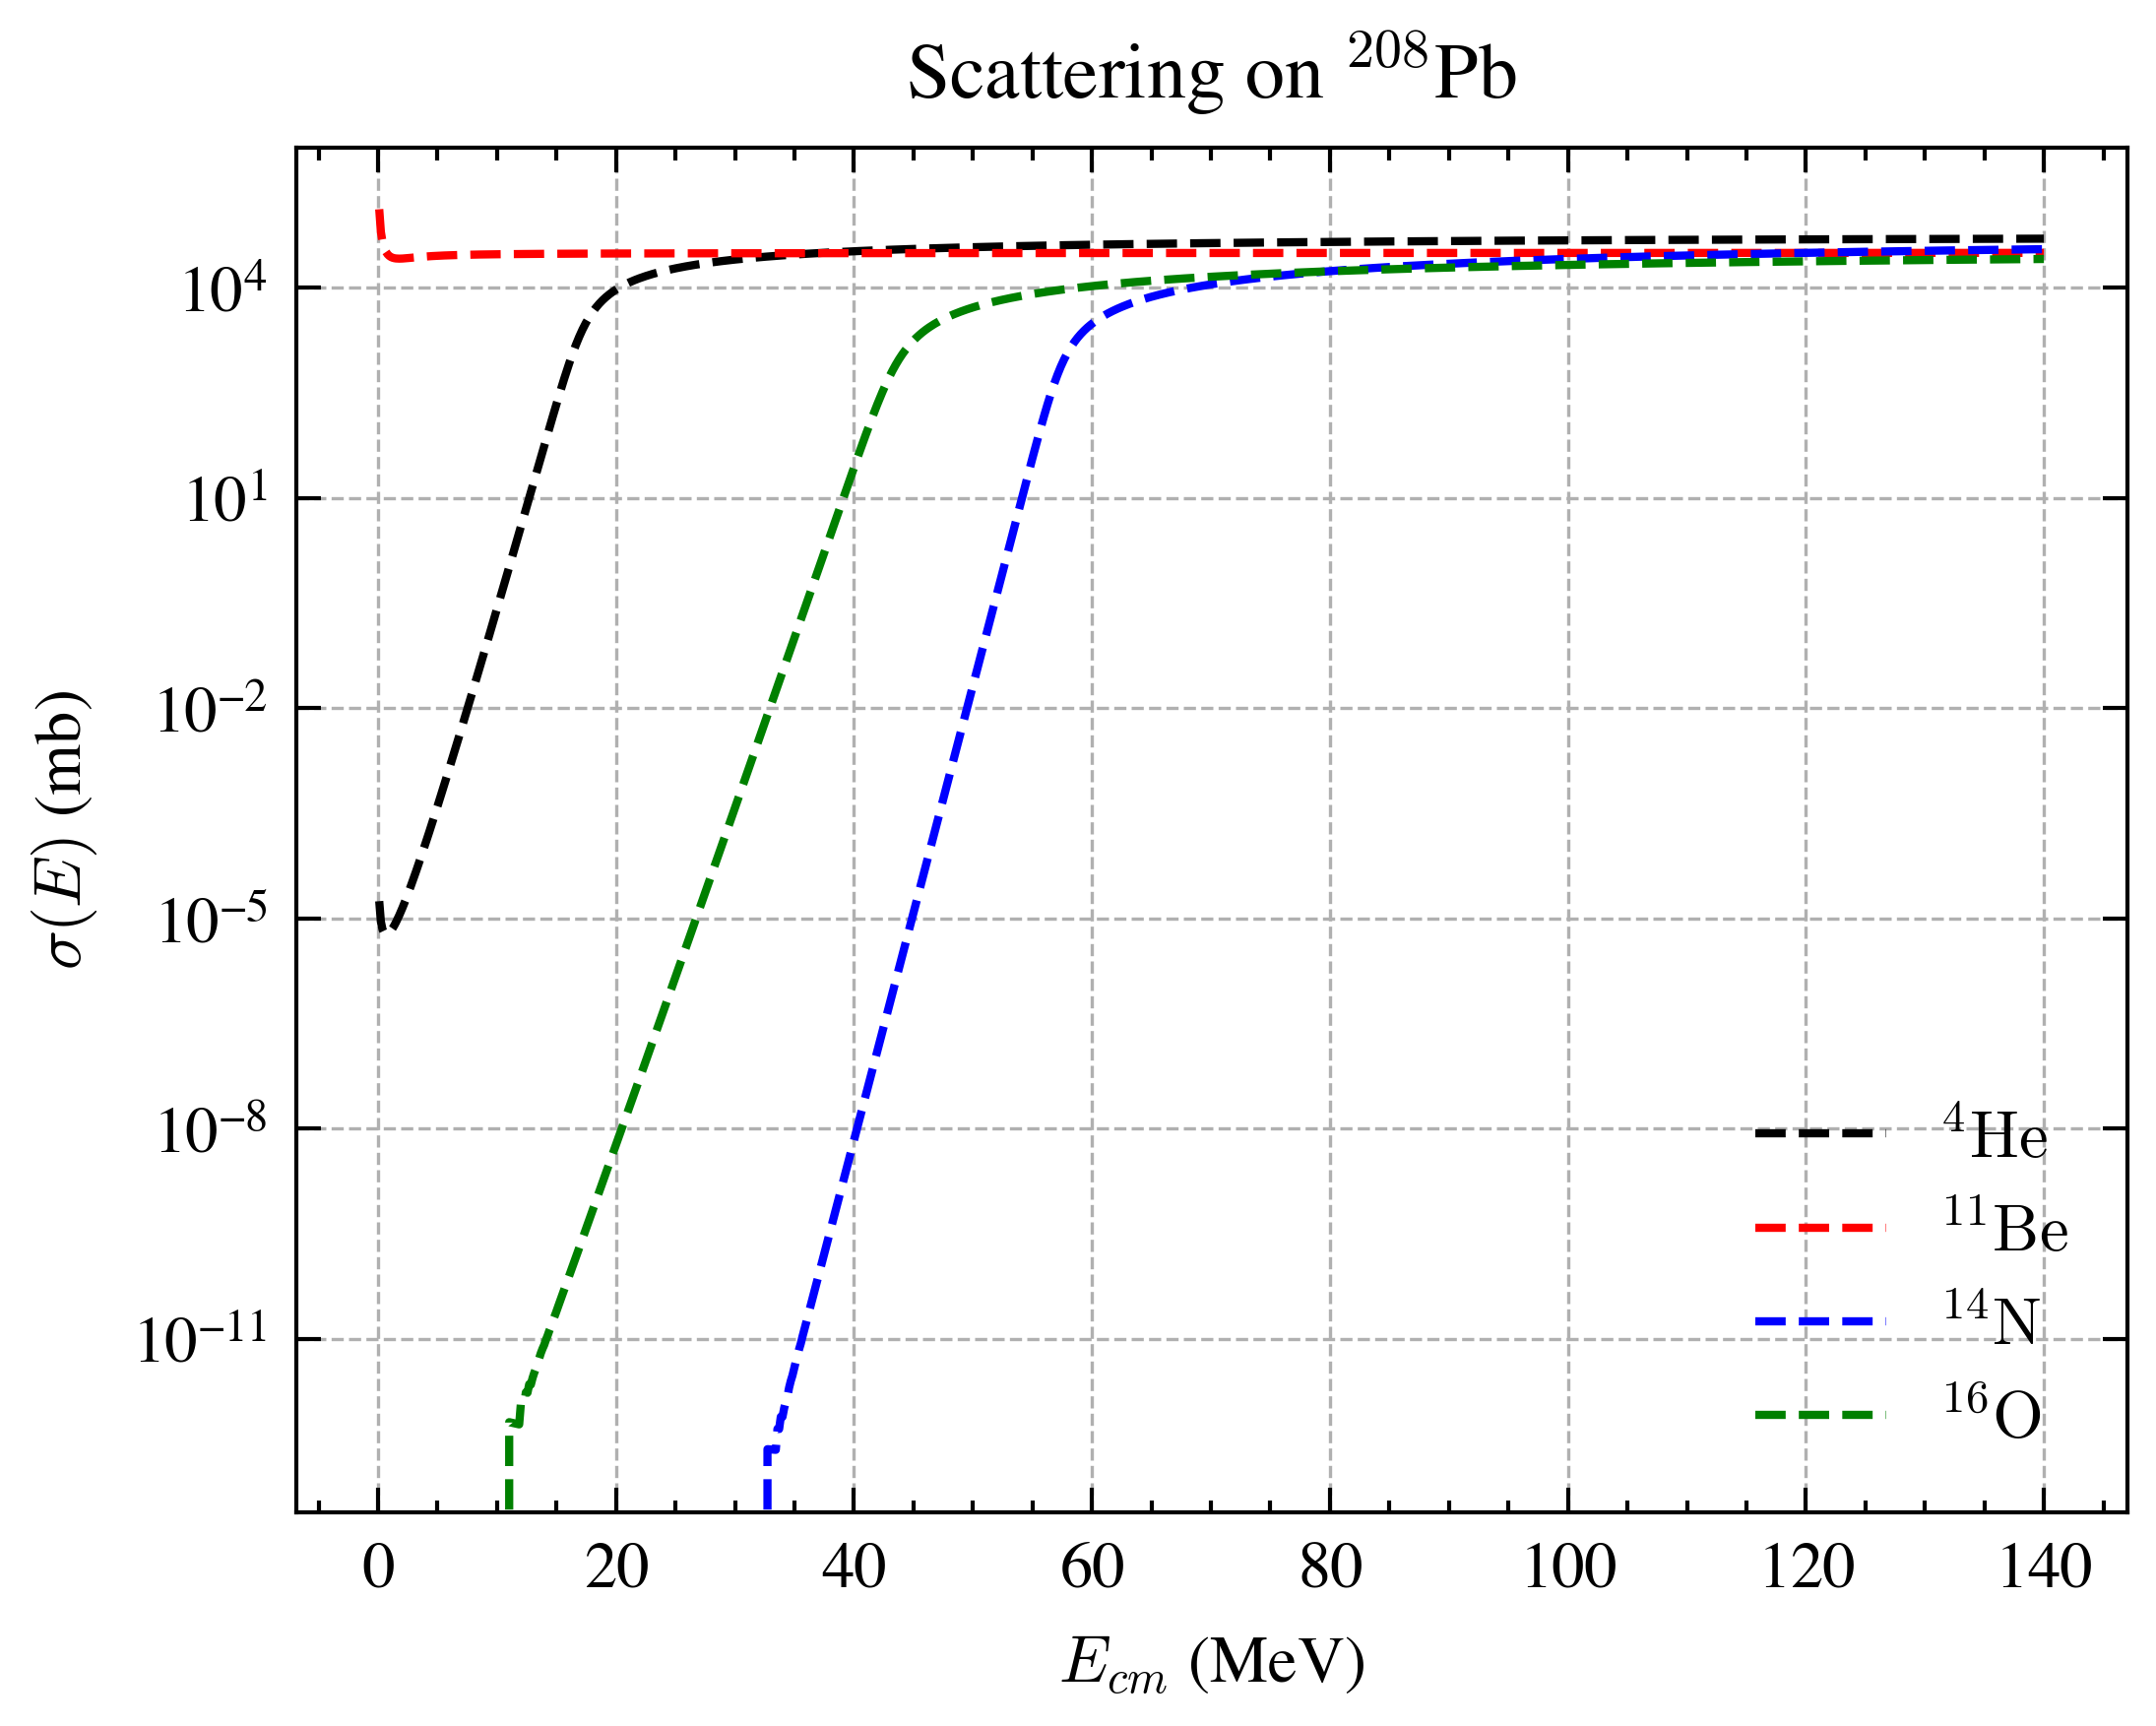

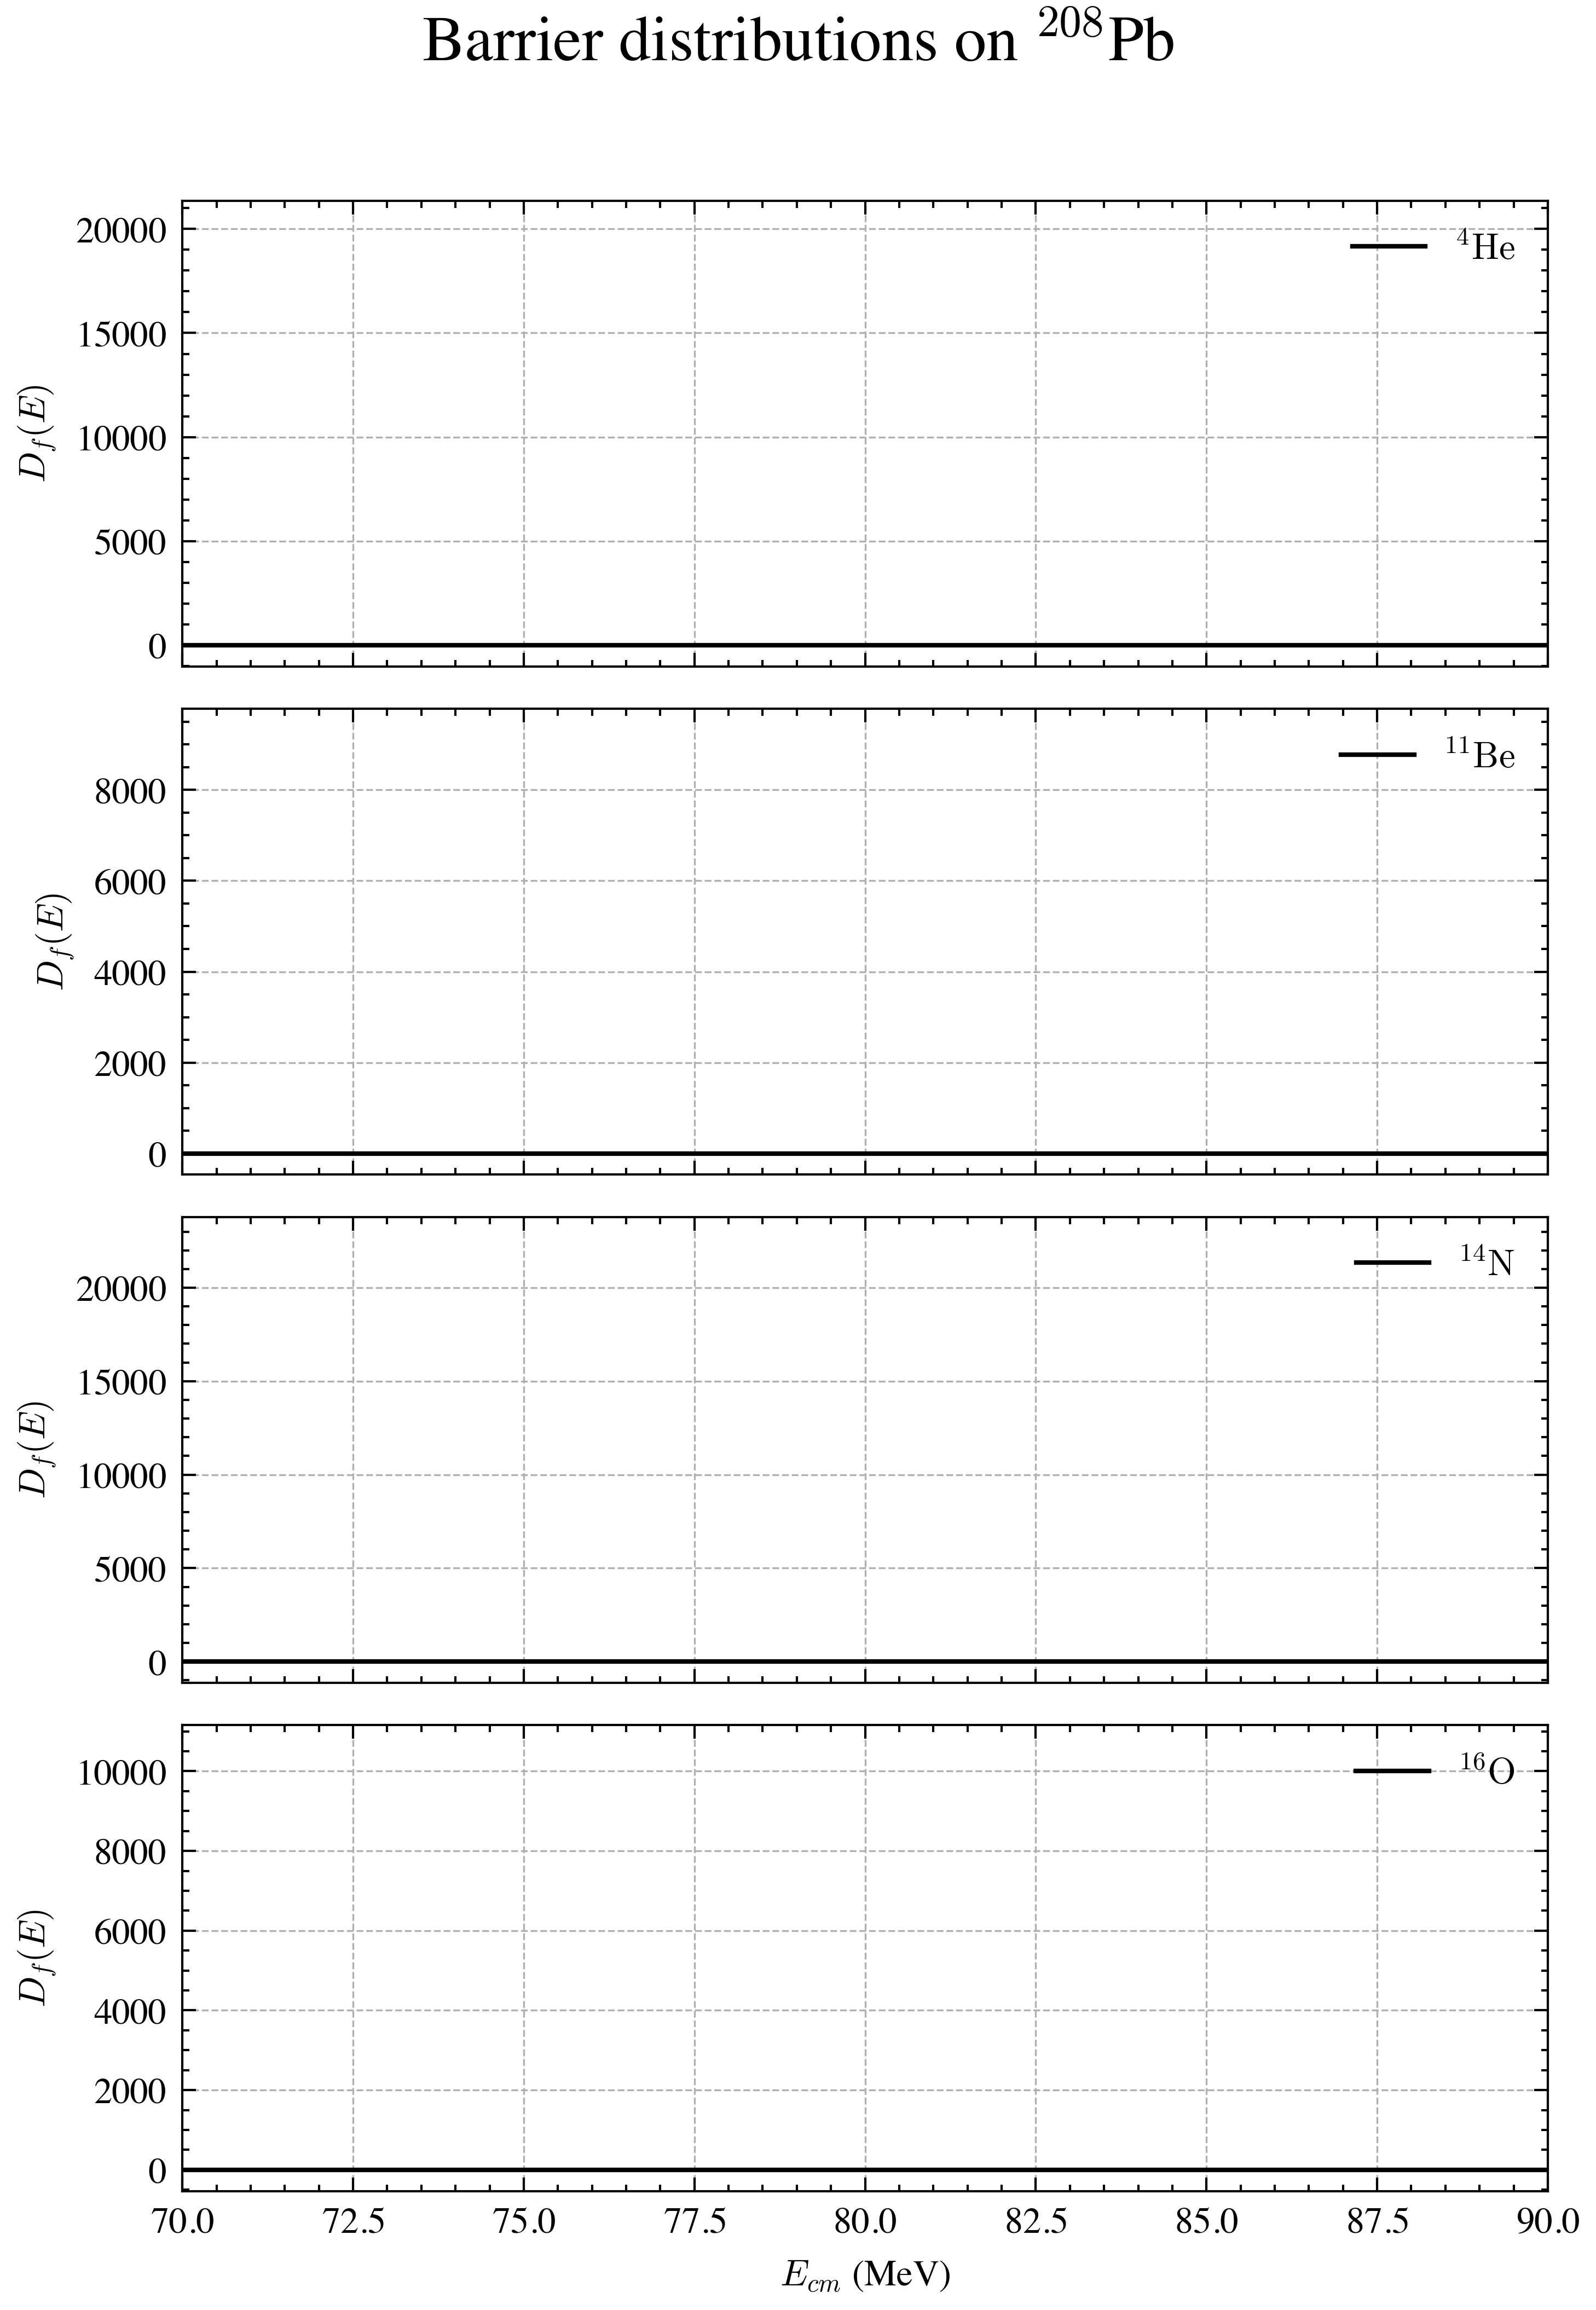

In [5]:
# projectiles
projectiles = [
    (r"$^4\mathrm{He}$",  4,  2),
    (r"$^{11}\mathrm{Be}$", 11, 4),
    (r"$^{14}\mathrm{N}$",  14, 7),
    (r"$^{16}\mathrm{O}$",  16, 8),
    # (r"$^{40}\mathrm{Ar}$", 40, 18),
]

# Target: 208Pb
A_t, Z_t = 208, 82

# 1 fm² = 10 mb
fm2_to_mb = 10.0

# Energies from ≈0 (avoid exact zero) up to 140 MeV
Es = np.linspace(0.1, 140.0, 1000)

# Storage for cross sections
sigma_all = []

# First plot: σ(E)
plt.figure(figsize=(4, 3))
for name, A_p, Z_p in projectiles:
    model = WongCrossSection(A_p, Z_p, A_t, Z_t)
    sigma_vals = model.sigma(Es) * fm2_to_mb
    sigma_all.append(sigma_vals)  # store this one
    
    plt.plot(Es, sigma_vals, label=name, linestyle='--')

plt.yscale("log")
#plt.ylim(1, 1e4)
plt.xlabel("$E_{cm}$ (MeV)")
plt.ylabel("$\\sigma(E)$ (mb)")
plt.title("Scattering on $^{208}$Pb")
plt.legend(fontsize='medium', loc='best')
plt.grid(linestyle="--", linewidth=0.4)
plt.show()


# Now compute and plot D_f(E) in subplots
num_proj = len(projectiles)
fig, axes = plt.subplots(num_proj, 1, figsize=(5, 1.8 * num_proj), sharex=True)

for ax, ((name, A_p, Z_p), sigma_vals) in zip(axes, zip(projectiles, sigma_all)):
    diff_dist = barrier_dist_discrete(Es, sigma_vals) 
    ax.plot(Es, diff_dist, label=name)
    ax.set_ylabel(r"$D_f(E)$")
    ax.set_xlim(70,90)
    # no manual ylim — let it autoscale naturally
    ax.legend(loc='best', fontsize='medium')
    ax.grid(linestyle="--", linewidth=0.4)

axes[-1].set_xlabel("$E_{cm}$ (MeV)")
fig.suptitle("Barrier distributions on $^{208}$Pb", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle
plt.show()

7.4794977996423935

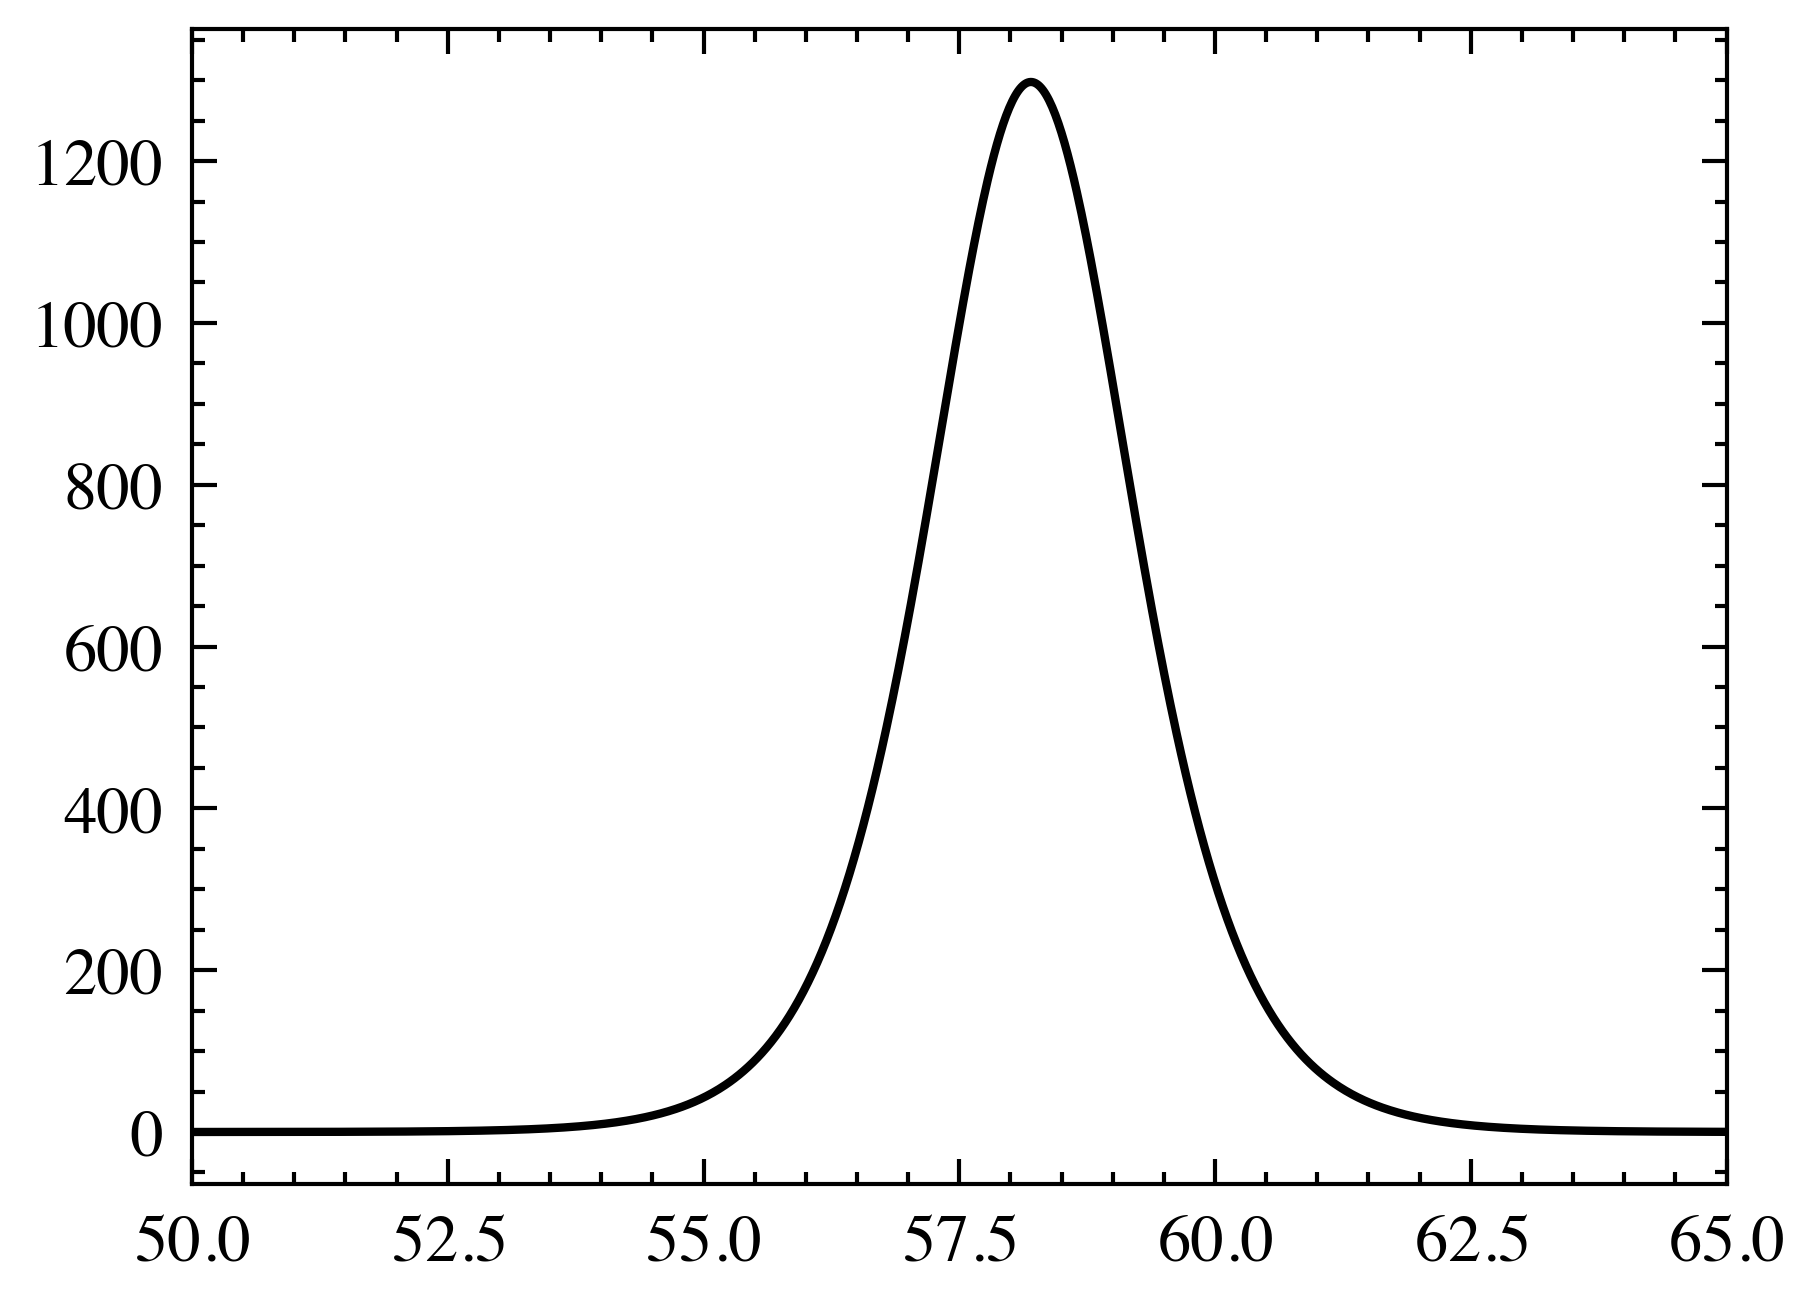

In [12]:
# 1 fm² = 10 mb
fm2_to_mb = 10.0

# Target: 64Ni
A_t, Z_t = 64, 28
A_p, Z_p = 24, 16
Es = np.linspace(50, 65, 1000)
model = WongCrossSection(A_p, Z_p, A_t, Z_t, r0=1.25, a=0.52,V0=65.0)
sigma_vals = model.sigma(Es) 
rB_guess = 1.25 * (A_t**(1/3) + A_p**(1/3))  # approximate barrier radius
r = np.linspace(2, 20, 200)
#plt.plot(model._r_arr, model._V_arr)
#plt.show()

#plt.plot(model._r_arr, model.V_prime(model._r_arr))
#plt.vlines(rB_guess, ymin=0, ymax=200)
x = 2 * np.pi * (Es - 58.2) / 4.2
D_f = 10*np.pi * (10.51)**2 * 2*np.pi / 4.2 * np.exp(x) / (1+np.exp(x))**2
plt.plot(Es,D_f)
plt.xlim(50,65)
model.RB

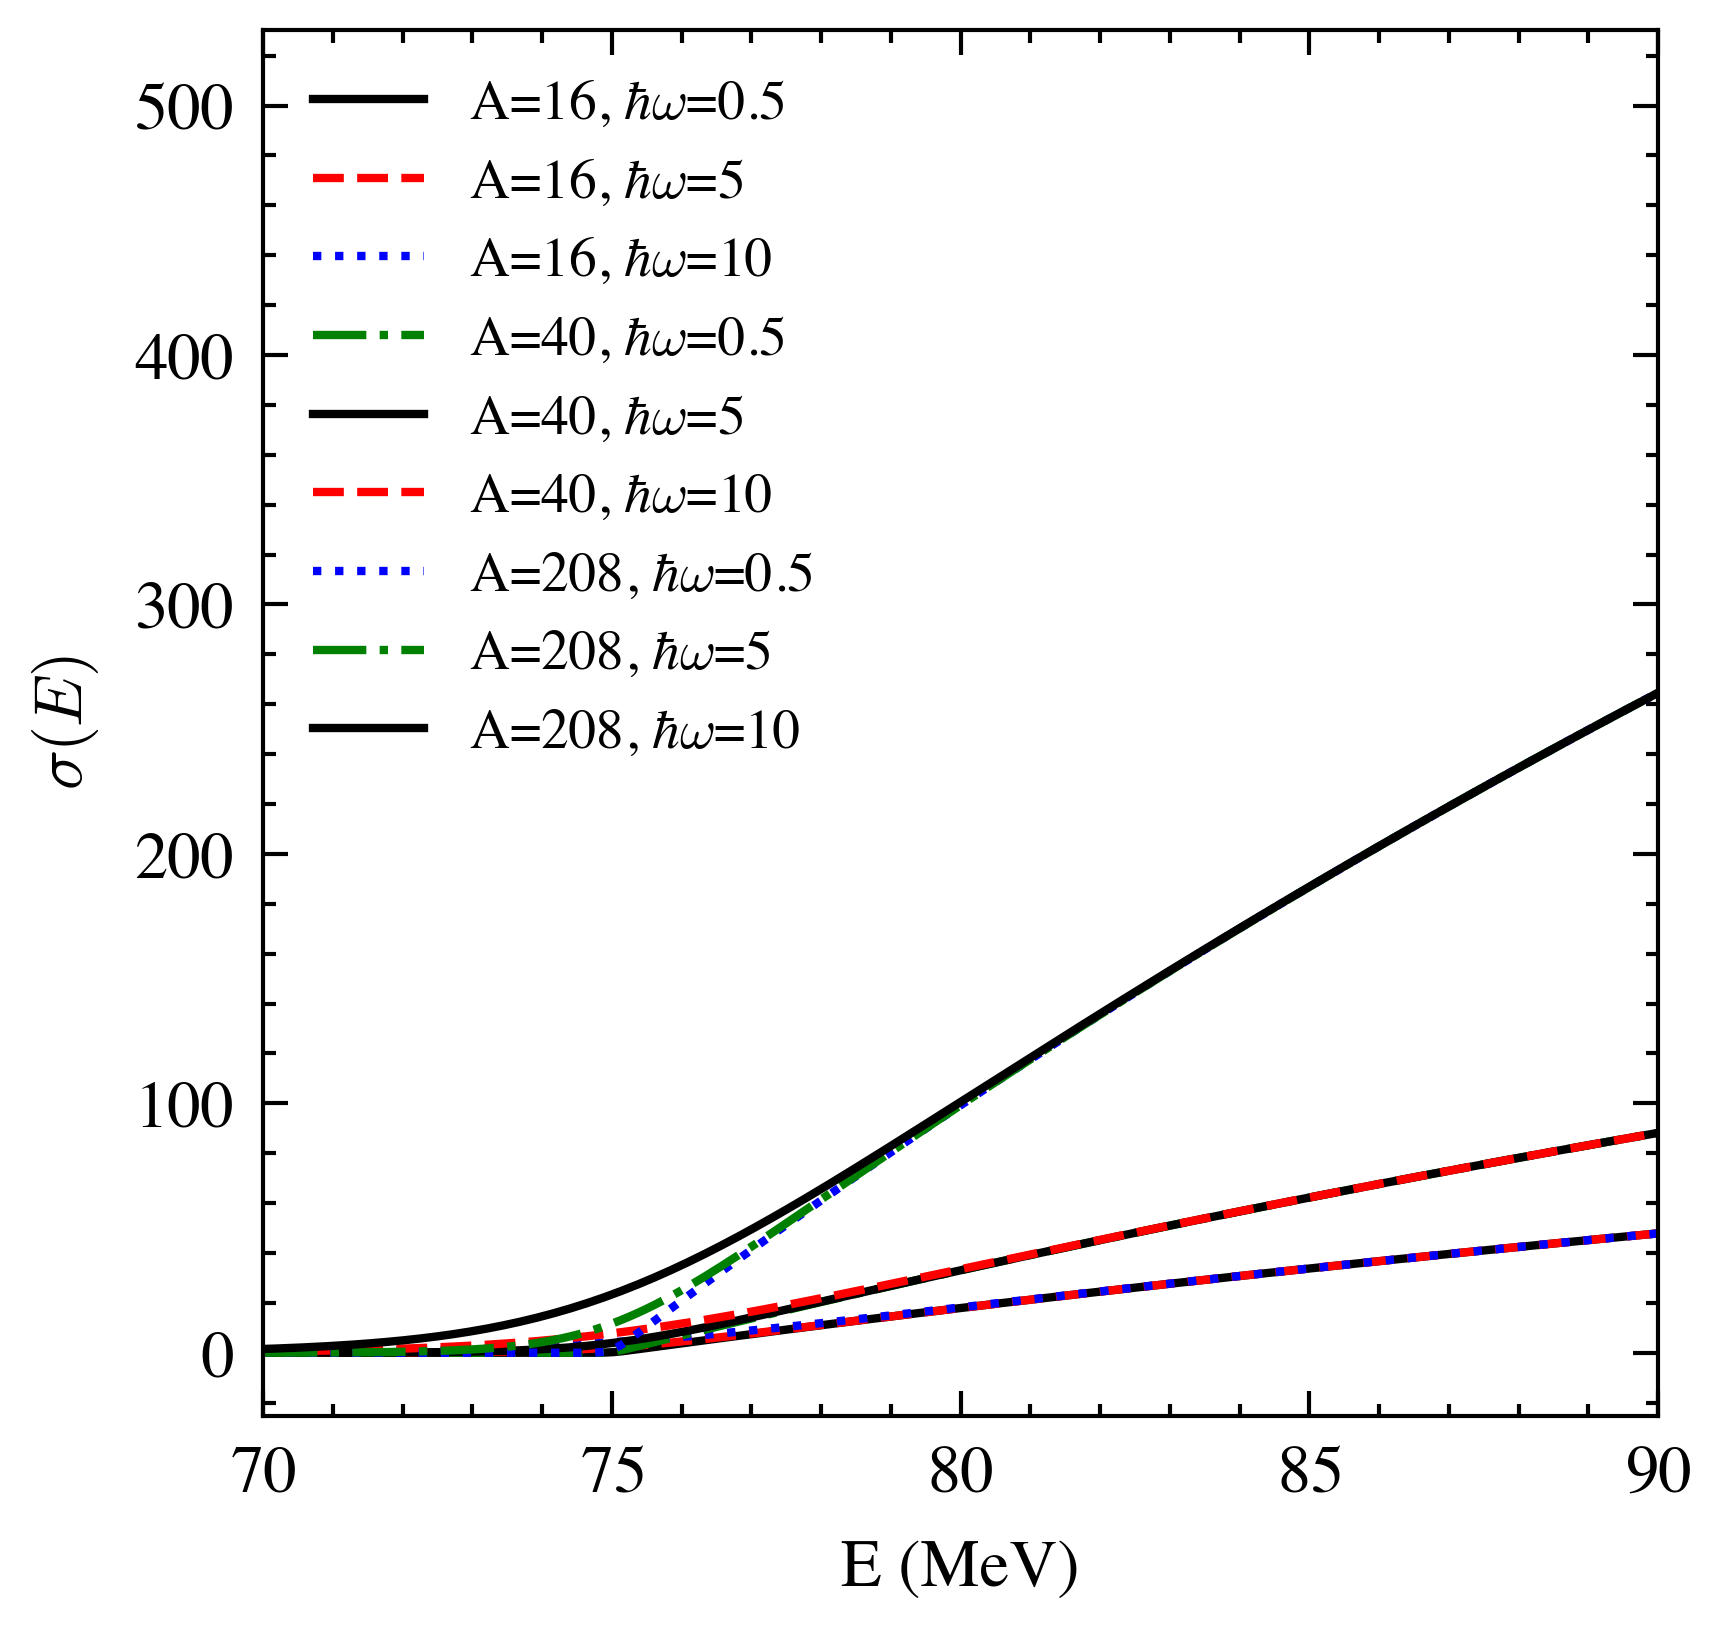

In [13]:
A_variations = [16, 40, 208]      # e.g., slightly below and above 208
hbarw_variations = [0.5, 5, 10]      # e.g., slightly below and above 5

plt.figure(figsize=(3, 3))

# Loop over variations of A and hbarw and plot each result
for A in A_variations:
    for hbarw in hbarw_variations:
        sigma_f = 10 * sigma(E, A=A, hbarw=hbarw, E0=75)
        label = rf"A={A}, $\hbar\omega$={hbarw}"
        plt.plot(E, sigma_f, label=label)

plt.xlabel("E (MeV)")
plt.ylabel(r"$\sigma(E)$")
plt.xlim(70, 90)
#plt.yscale('log')
plt.legend(fontsize='small', loc='best')
plt.savefig("plots/WongSampleCrossSection.png")
plt.show()


In [14]:
diff_dist = barrier_dist_discrete(E, sigma_f)

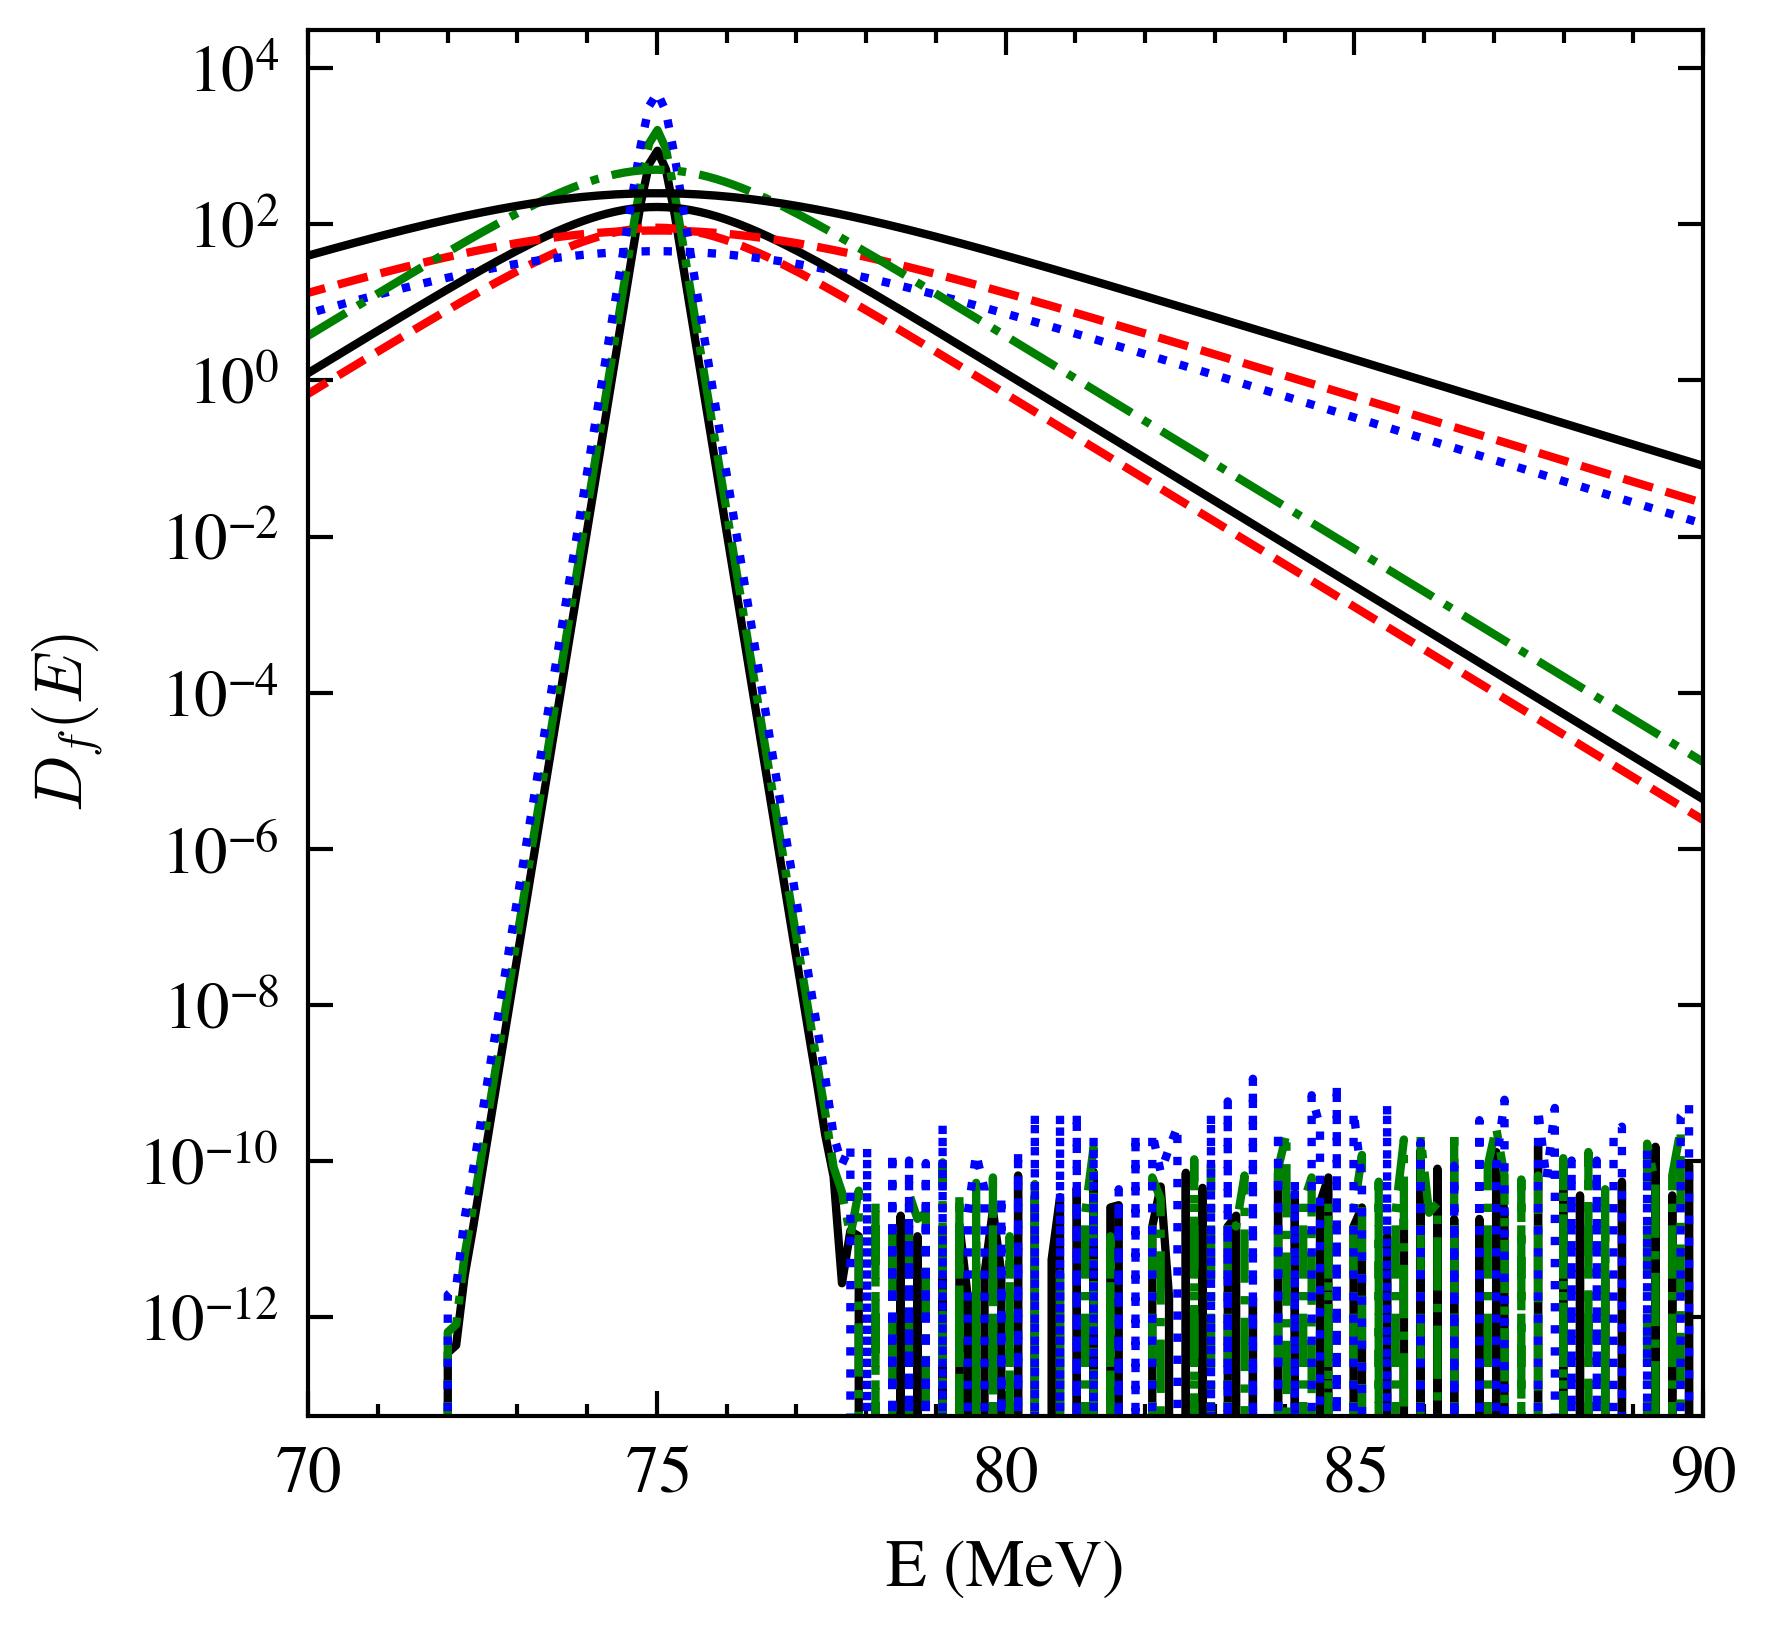

In [15]:
plt.figure(figsize=(3, 3))
for A in A_variations:
    for hbarw in hbarw_variations:
        sigma_f = 10 * sigma(E, A=A, hbarw=hbarw, E0=75)
        diff_dist = barrier_dist_discrete(E, sigma_f)
        label = rf"A={A}, $\hbar\omega$={hbarw}"
        plt.plot(E, diff_dist, label=label)

plt.xlabel("E (MeV)")
plt.ylabel(r"$D_{f}(E)$")
plt.xlim(70, 90)
# plt.ylim(1e-9, 1e5)

#plt.legend(fontsize=4, loc='best')
plt.yscale("log")
plt.savefig("plots/WongSampleDistribution.png")
plt.show()

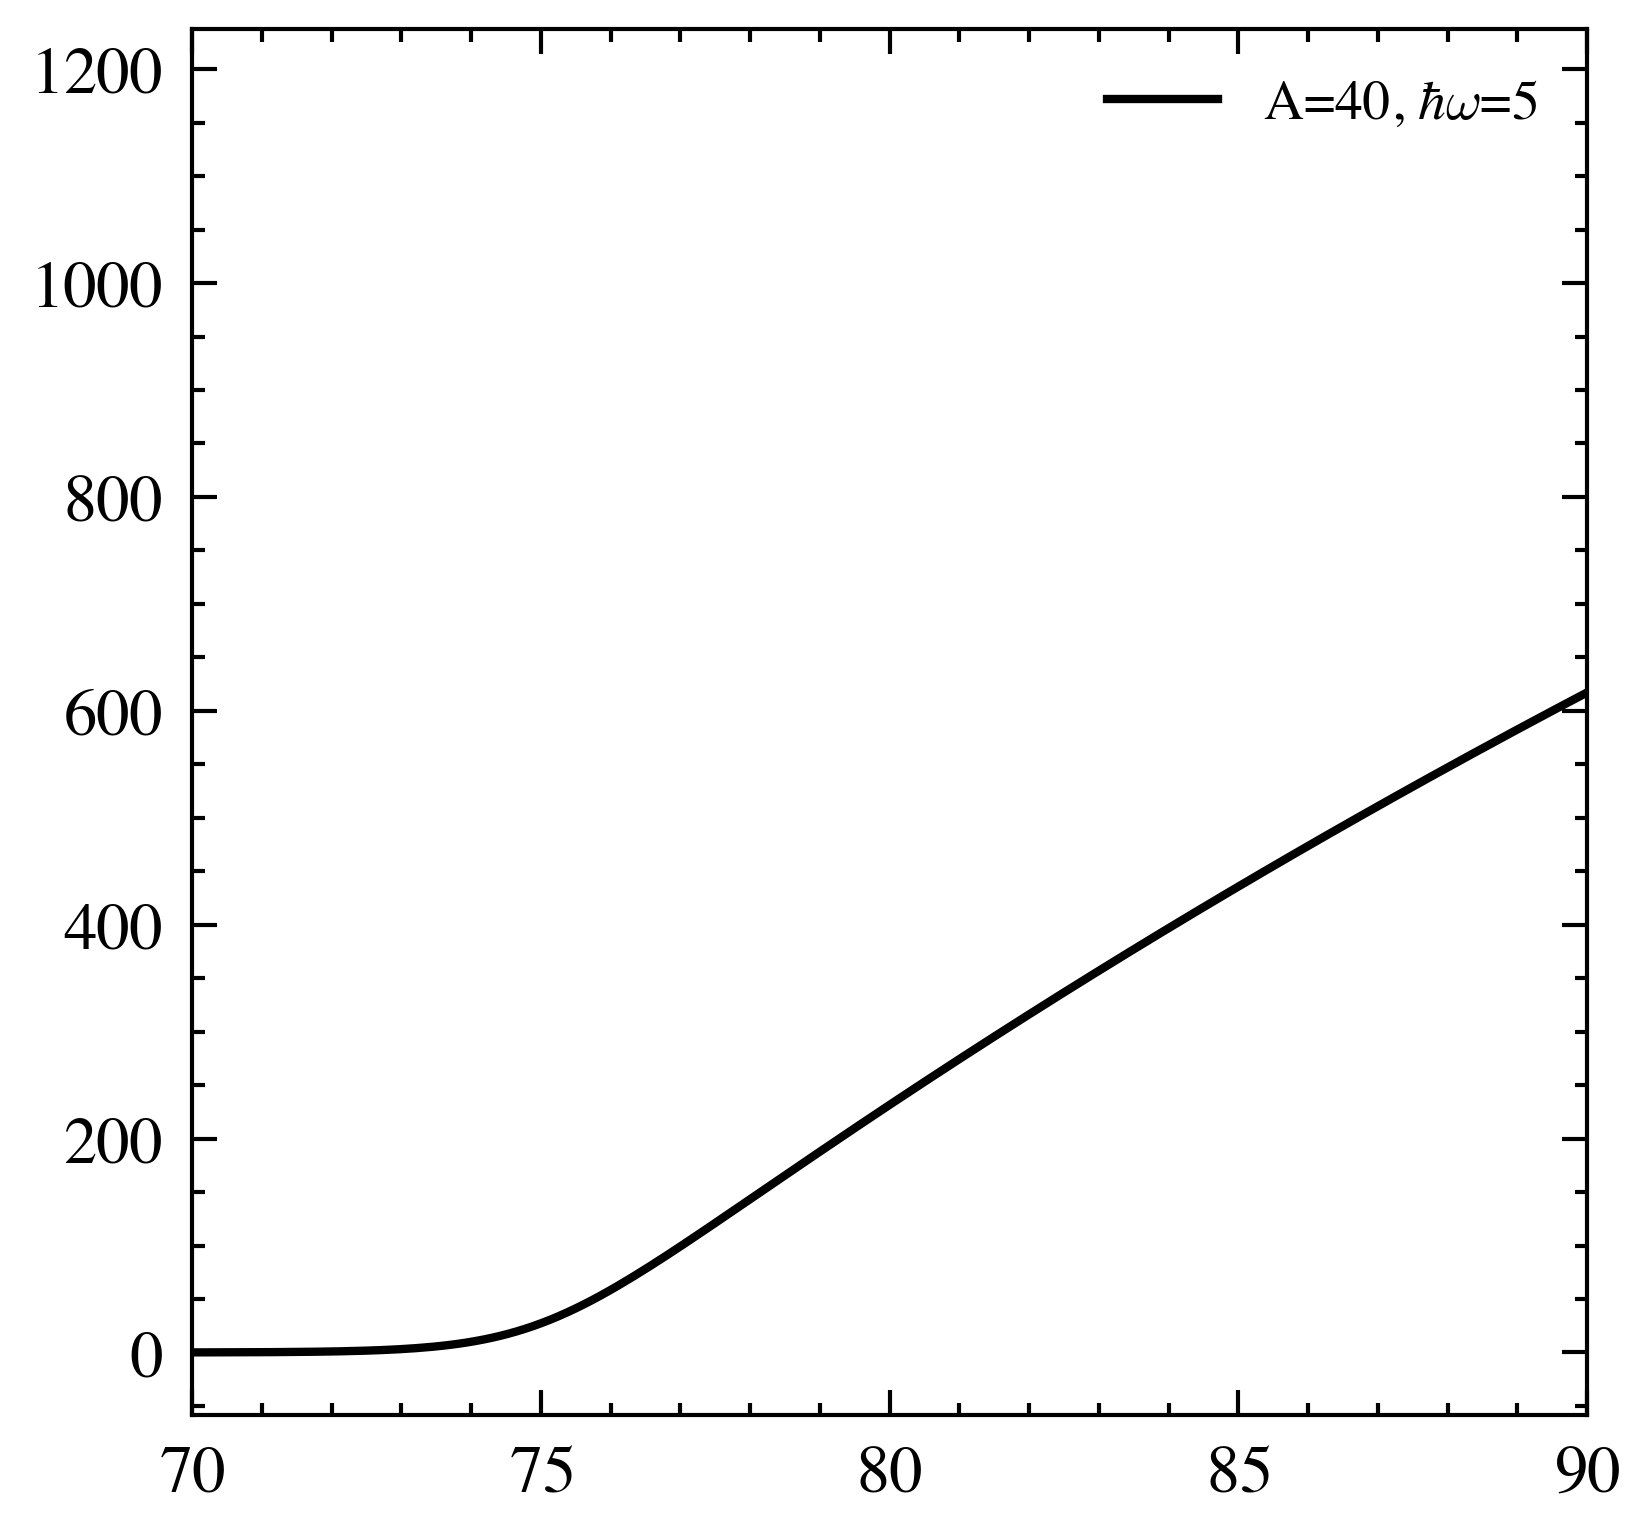

In [16]:
A = 40
hbarw = 5
sigma_f = 70 * sigma(E, A=A, hbarw=hbarw, E0=75)
plt.figure(figsize=(3, 3))
plt.plot(E, sigma_f, label=rf"A={A}, $\hbar\omega$={hbarw}")
plt.xlim(70, 90)
#plt.yscale('log')
plt.legend(fontsize='small', loc='best')

'\ngp.fit(E[0:end:skip].reshape(-1,1), sigma_f[0:end:skip])\n\nx_pred = np.linspace(E[0],E[-1], 200)\ny_pred, sigma_gp = gp.predict(x_pred.reshape(-1,1), return_std=True)\nplt.plot(x_pred, y_pred, label="GP "+explabel[i],marker="",ls=\'-\',lw=0.5,color=expcolor[i])\nplt.fill_between(\nx_pred,\ny_pred - 1.96 * sigma_gp,\ny_pred + 1.96 * sigma_gp,\nalpha=0.5,\nlabel=r"95% confidence interval",)\n\nplt.xlim(70, 90)\nplt.ylim(-1, 1000)\n'

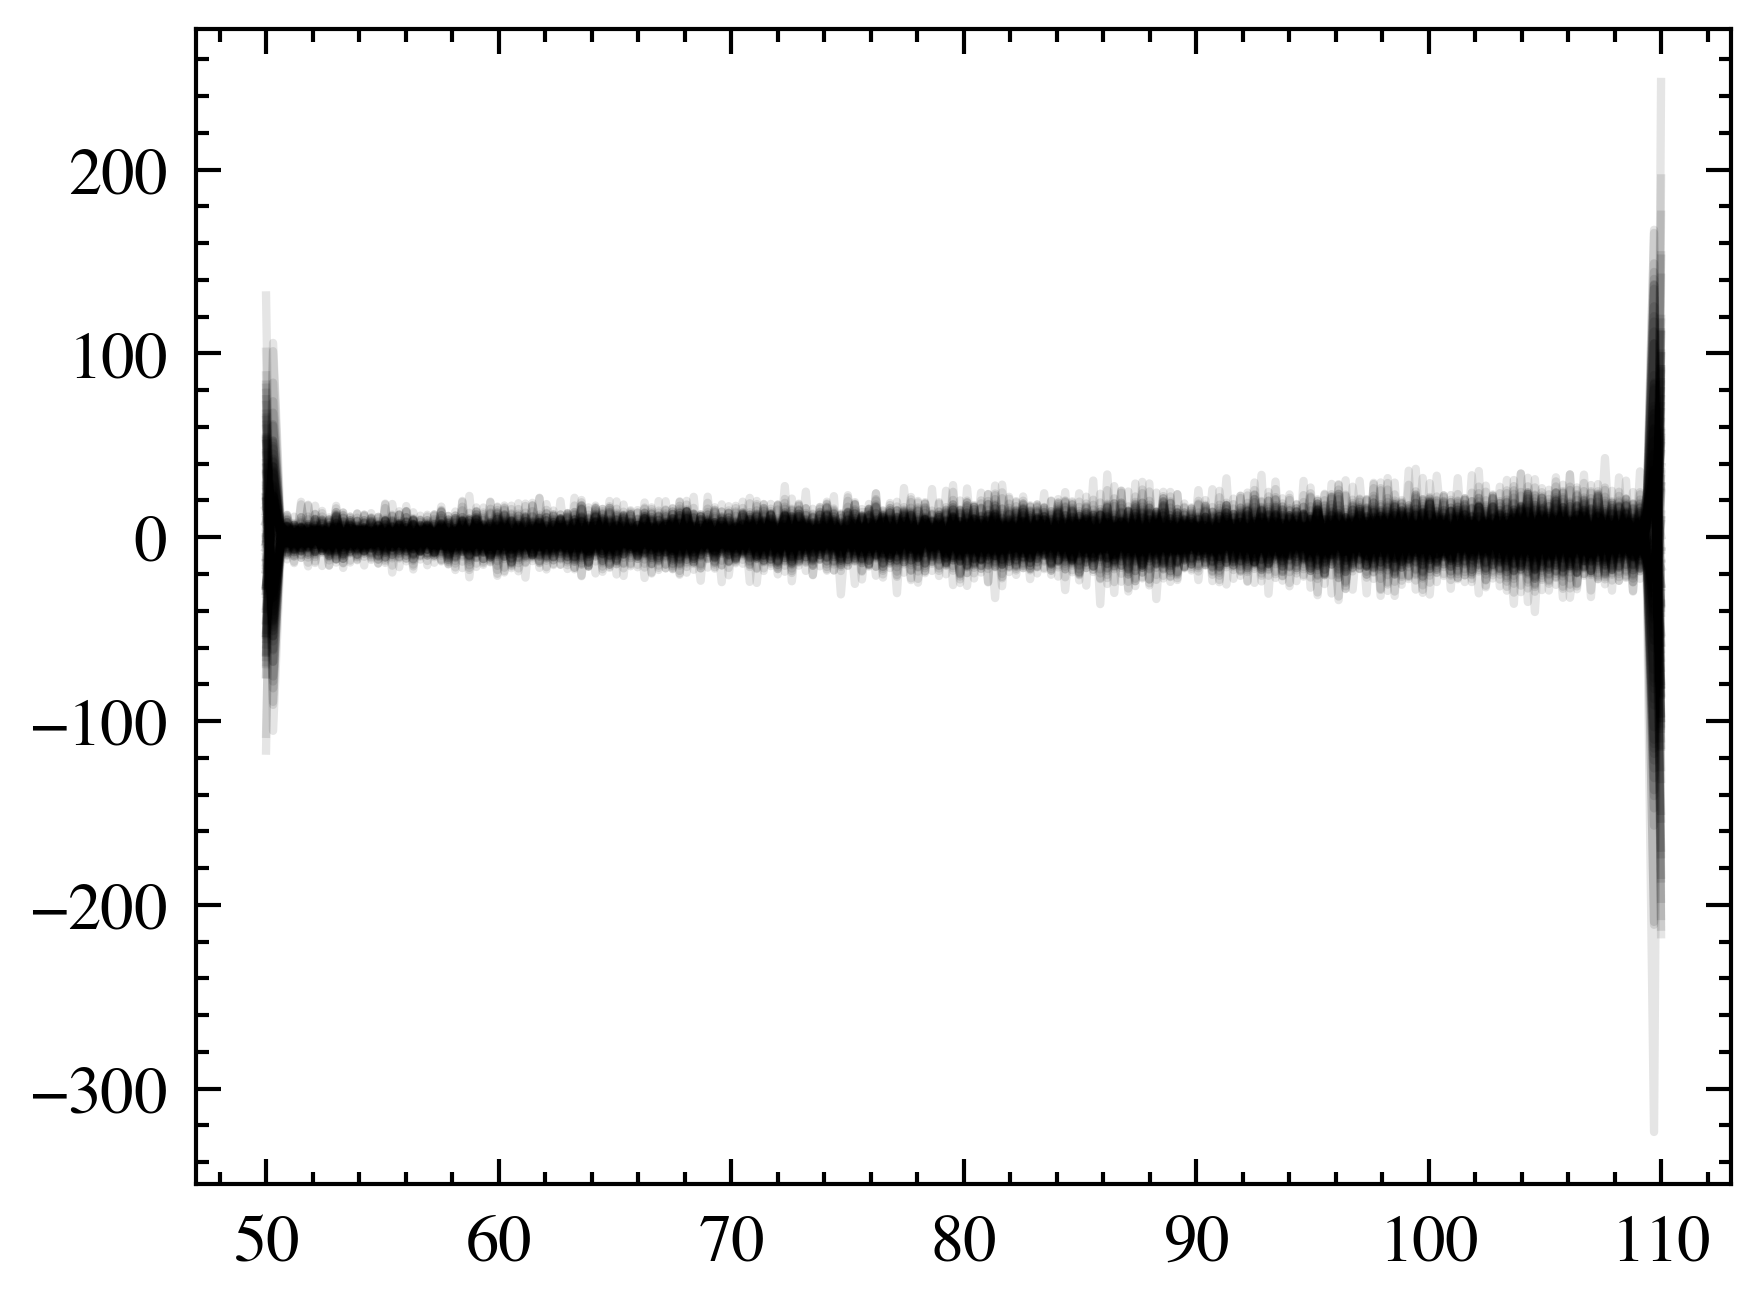

In [17]:

i = 1
skip = 5
end = -200
alpha = np.zeros(E[:end:skip].shape)+1e-5
#plt.plot(E[::skip],sigma_f[::skip],label=explabel[i],marker=expmarker[i],ls='',lw=0.5,ms=1,color=expcolor[i])
kernel = 1 * RBF(length_scale=10, length_scale_bounds=(np.abs(E[skip]-E[0]), 1e1))
kernel += 1 * WhiteKernel(noise_level=1e-5, noise_level_bounds=(1e-9, 1e-3))
gp = GaussianProcessRegressor(kernel=kernel,alpha=alpha, n_restarts_optimizer=20)
x_pred = np.linspace(E[0],E[-1], 200)

nsamps = 100
y_samps = gp.sample_y(x_pred.reshape(-1,1), nsamps)
ndist = np.zeros((len(x_pred),nsamps))
dE=1
#dist, err = point_diff(E[::skip],E[::skip]*sigma_f[::skip],std=np.zeros(E[::skip].shape)+1e-2,dE=dE)
#plt.plot(E[::skip][dE:-dE],(-dist[dE:-dE]),label=explabel[0],marker=expmarker[0],ls='',lw=1,ms=4,color=expcolor[0])

for j in range(nsamps):
    ndist[:,j] = barrier_dist(x_pred,y_samps[:,j])
    # ndist[:,j] = -ndist[:,j]/np.max(np.abs(ndist[:,j]))
    plt.plot(x_pred,ndist[:,j],marker="",ls='-',lw=1,ms=0,alpha=0.1, color='black')
#plt.ylim([-200,1200])
#plt.xlim(70, 90)

"""
gp.fit(E[0:end:skip].reshape(-1,1), sigma_f[0:end:skip])

x_pred = np.linspace(E[0],E[-1], 200)
y_pred, sigma_gp = gp.predict(x_pred.reshape(-1,1), return_std=True)
plt.plot(x_pred, y_pred, label="GP "+explabel[i],marker="",ls='-',lw=0.5,color=expcolor[i])
plt.fill_between(
x_pred,
y_pred - 1.96 * sigma_gp,
y_pred + 1.96 * sigma_gp,
alpha=0.5,
label=r"95% confidence interval",)

plt.xlim(70, 90)
plt.ylim(-1, 1000)
"""

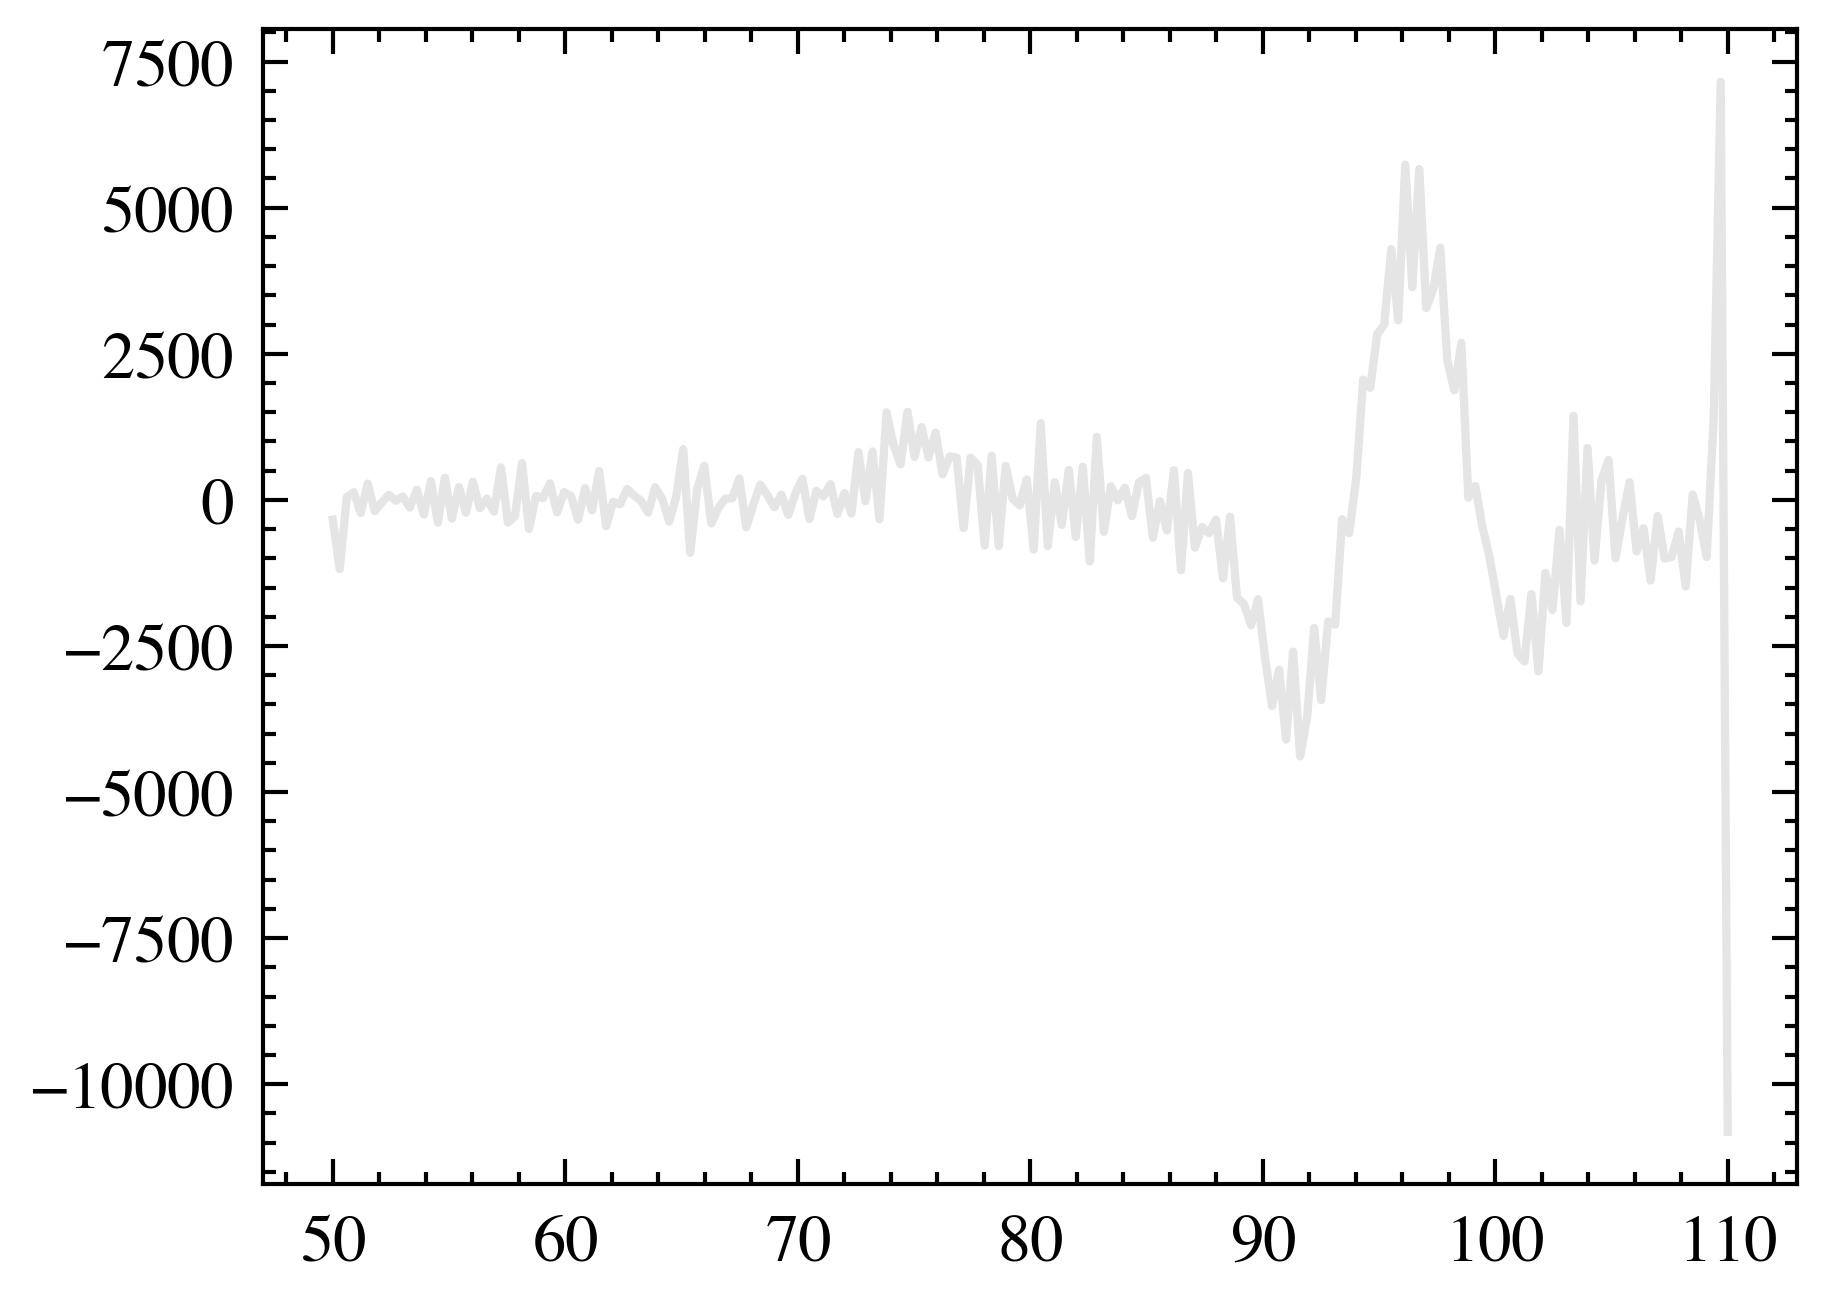

(70.0, 90.0)

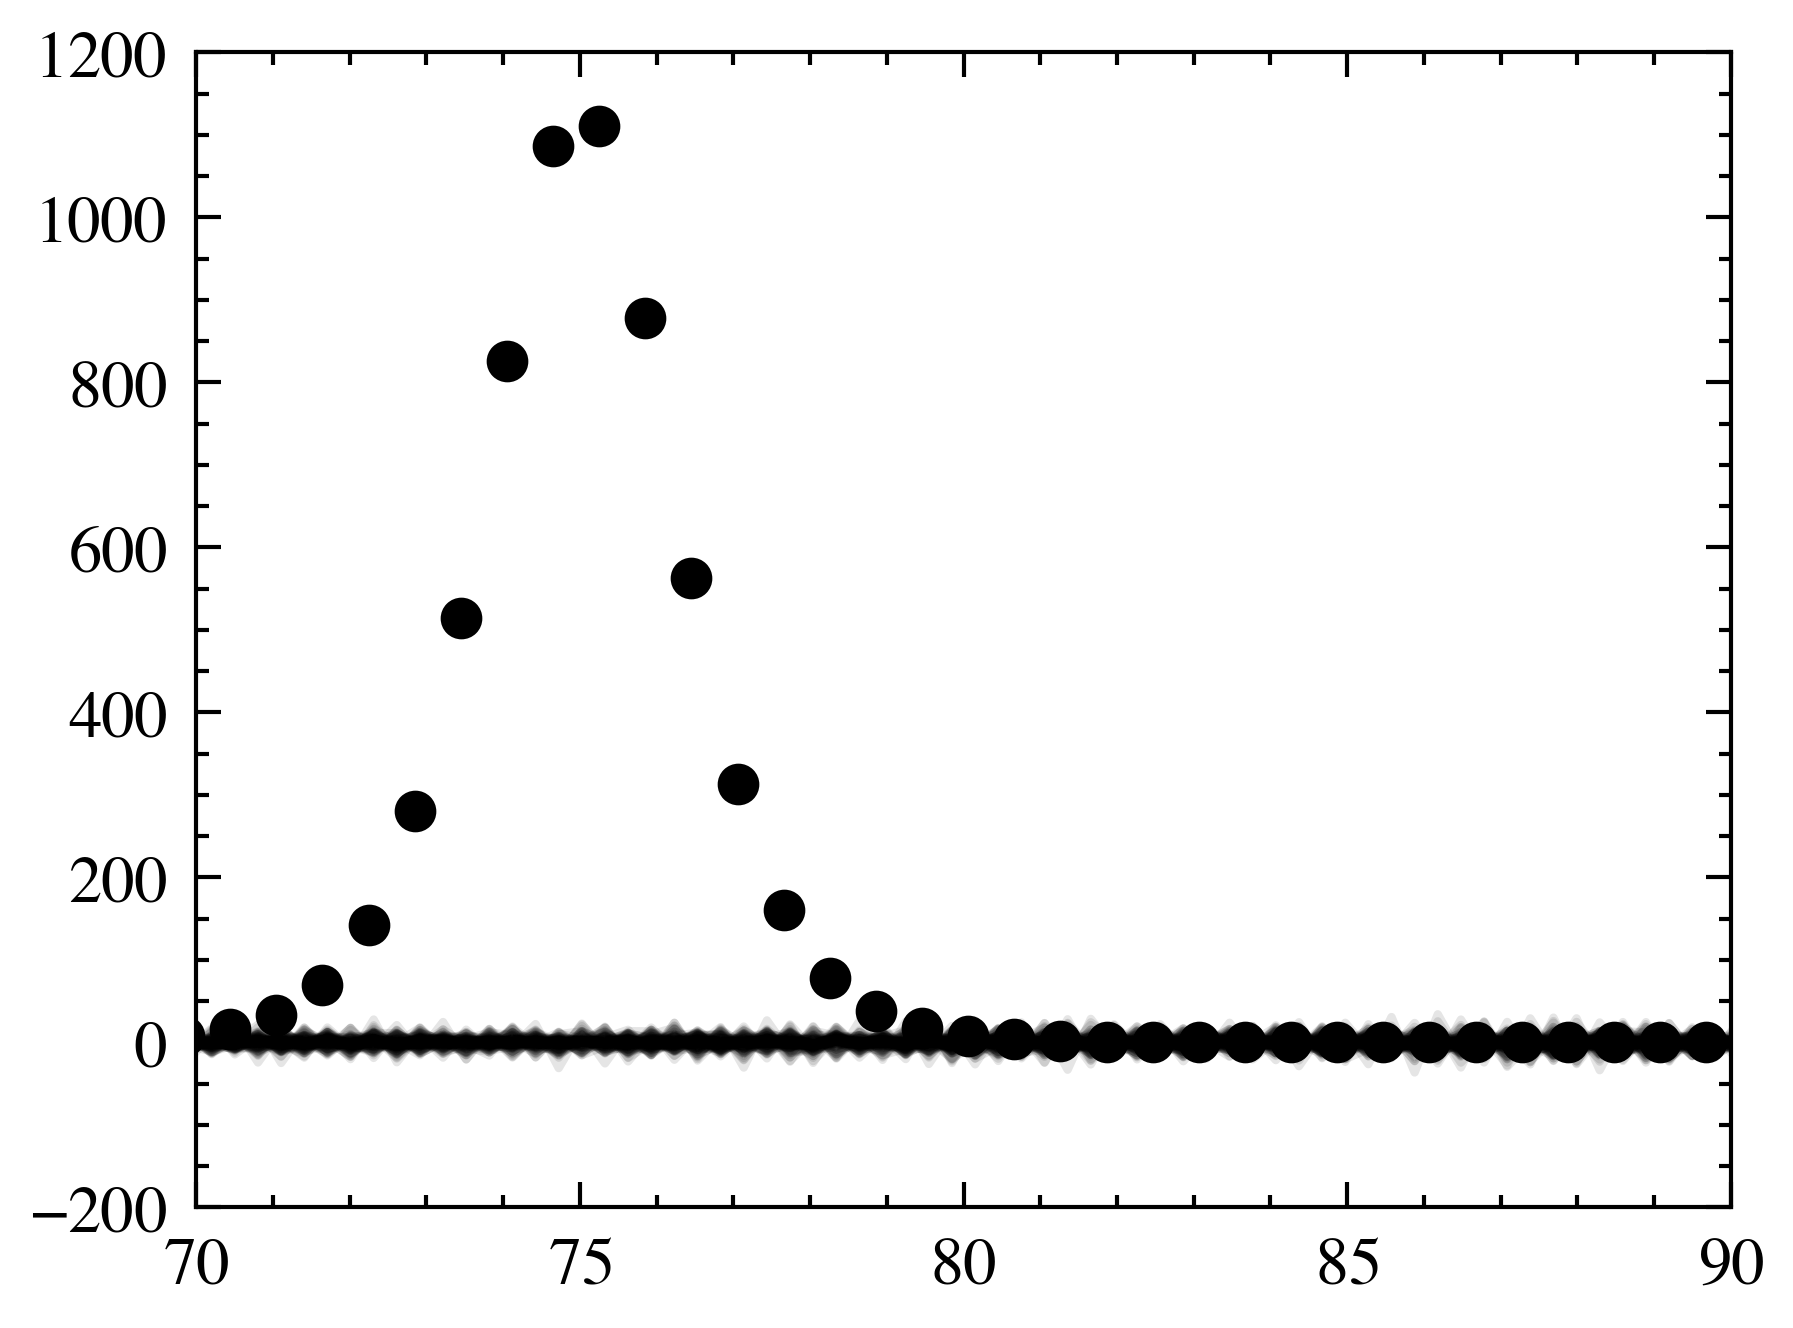

In [18]:
nsamps = 100
y_samps = gp.sample_y(x_pred.reshape(-1,1), nsamps)
ndist = np.zeros((len(x_pred),nsamps))
dE=1
dist, err = point_diff(E[::skip],E[::skip]*sigma_f[::skip],std=np.zeros(E[::skip].shape)+1e-2,dE=dE)
plt.plot(E[::skip][dE:-dE],(-dist[dE:-dE]),label=explabel[0],marker=expmarker[0],ls='',lw=1,ms=4,color=expcolor[0])

for j in range(nsamps):
    ndist[:,j] = barrier_dist(x_pred,y_samps[:,j])
    # ndist[:,j] = -ndist[:,j]/np.max(np.abs(ndist[:,j]))
    plt.plot(x_pred,ndist[:,j],marker="",ls='-',lw=1,ms=0,alpha=0.1, color='black')
plt.ylim([-200,1200])
plt.xlim(70, 90)



(70.0, 90.0)

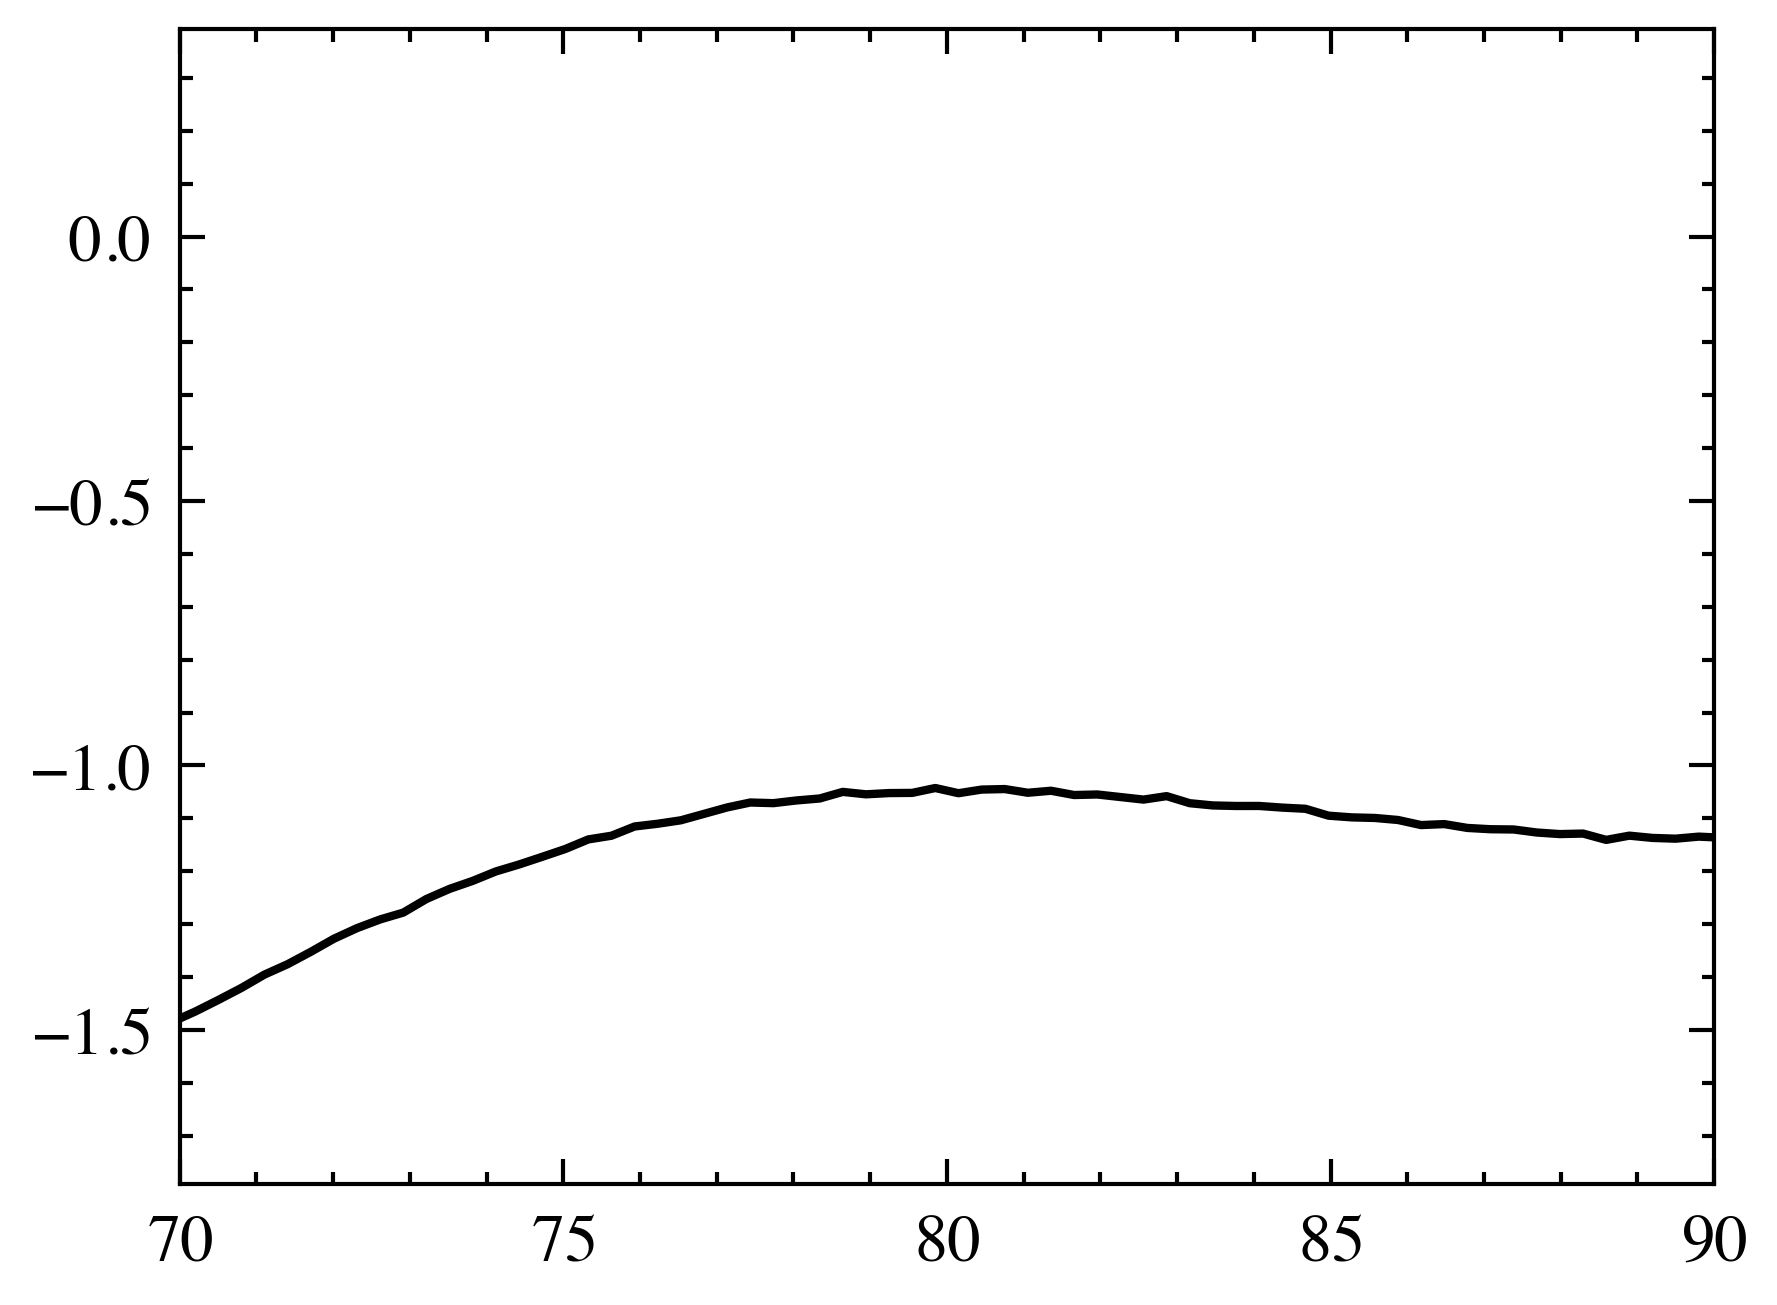

In [19]:
plt.plot(x_pred, y_samps[:,15])
plt.xlim(70, 90)